# Strang分割および高次Lie-Trotter分解による微分方程式の解法と誤差解析

このノートブックでは、微分方程式 $\frac{df}{dt} = (A + B)f$ をStrang分割（Strang Splitting）を用いて近似解法し、厳密解と比較することでその精度と非可換性の影響を視覚化します。

In [96]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from scipy.linalg import expm
from IPython.display import HTML

# --- 1. パラメータ設定 ---
# 行列 A, B の定義（非可換な系を想定）
A = np.array([[-0.4, 0.0], [0.0, -1.0]])
B = np.array([[0.0, 0.0], [1.0, 0.0]])

# 交換子 [A, B] を計算して非可換性を確認
print("Commutator [A, B]:\n", A @ B - B @ A)

dt = 0.5        # 時間刻み幅
steps = 40      # ステップ数
f0 = np.array([1.0, 0.1]) # 初期状態

# --- 2. 各分割手法の定義 ---

# Lie-Trotter分割 (1次精度): e^(At) * e^(Bt)
def lie_step_with_intermediates(f, dt, A, B):
    f1 = expm(A * dt) @ f
    f2 = expm(B * dt) @ f1
    return f1, f2  # 2つのサブステップを返す

# Strang分割 (2次精度): e^(A*t/2) * e^(Bt) * e^(A*t/2)
def strang_step_with_intermediates(f, dt, A, B):
    f1 = expm(A * dt / 2) @ f
    f2 = expm(B * dt) @ f1
    f3 = expm(A * dt / 2) @ f2
    return f1, f2, f3  # 3つのサブステップを返す

# Suzuki-Trotter分解 (4次精度): 5つのStrangステップの組み合わせ
def suzuki_4th_order_step_with_intermediates(f, dt, A, B):
    p = 1.0 / (4.0 - 4.0**(1.0/3.0))
    def strang_step_inter(v, t):
        s1 = expm(A * t / 2) @ v
        s2 = expm(B * t) @ s1
        s3 = expm(A * t / 2) @ s2
        return [s1, s2, s3]

    # 5つのサブインターバル幅
    steps_dt = [p*dt, p*dt, (1-4*p)*dt, p*dt, p*dt]
    all_subs = []
    curr = f
    for s_dt in steps_dt:
        subs = strang_step_inter(curr, s_dt)
        all_subs.extend(subs)
        curr = subs[-1]
    return all_subs  # 計15個のサブステップを返す

# --- 3. シミュレーション実行 ---
trajectory_lie_full = [f0]
trajectory_strang_full = [f0]
trajectory_suzuki_full = [f0]
trajectory_exact = [f0]
C = A + B  # 合成演算子 (A+B)

curr_f_lie = f0
curr_f_str = f0
curr_f_sz = f0

for i in range(1, steps + 1):
    # Lie法実行
    l1, l2 = lie_step_with_intermediates(curr_f_lie, dt, A, B)
    trajectory_lie_full.extend([l1, l2])
    curr_f_lie = l2

    # Strang法実行
    s1, s2, s3 = strang_step_with_intermediates(curr_f_str, dt, A, B)
    trajectory_strang_full.extend([s1, s2, s3])
    curr_f_str = s3

    # Suzuki法実行
    subs_sz = suzuki_4th_order_step_with_intermediates(curr_f_sz, dt, A, B)
    trajectory_suzuki_full.extend(subs_sz)
    curr_f_sz = subs_sz[-1]

    # 厳密解 (行列指数関数) - 比較用にサブステップ数(3)を合わせて記録
    f_ex = expm(C * (i * dt)) @ f0
    trajectory_exact.extend([f_ex, f_ex, f_ex])

# 可視化・解析用にnumpy配列に変換
trajectory_lie_full = np.array(trajectory_lie_full)
trajectory_strang_full = np.array(trajectory_strang_full)
trajectory_suzuki_full = np.array(trajectory_suzuki_full)
trajectory_exact = np.array(trajectory_exact)

Commutator [A, B]:
 [[ 0.   0. ]
 [-0.6  0. ]]


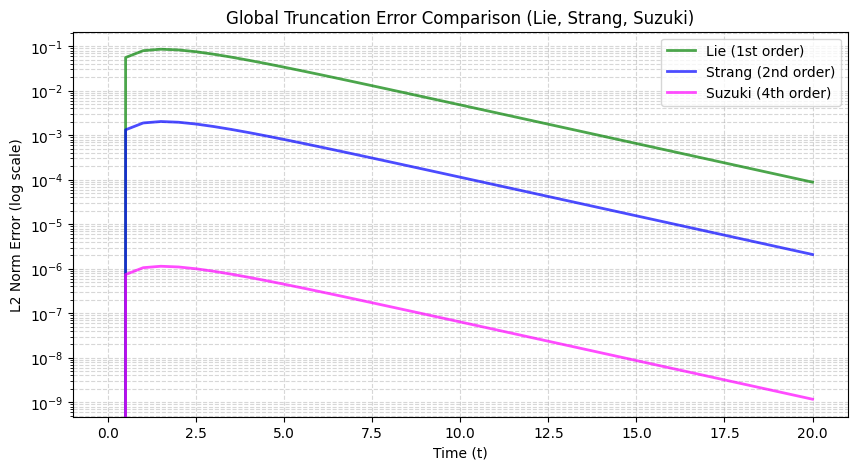

In [97]:
import matplotlib.pyplot as plt

# --- 誤差精度の比較プロット ---
plt.figure(figsize=(10, 5))
t_axis = np.linspace(0, steps*dt, steps+1)
exact_at_steps = trajectory_exact[::3] # 各 dt ごとの厳密解を抽出

# 各手法の累積誤差（L2ノルム）を計算
# Lie: 1ステップあたり2サブステップなので [::2] で各時刻の終端を抽出
err_lie = np.linalg.norm(trajectory_lie_full[::2] - exact_at_steps, axis=1)
# Strang: 1ステップあたり3サブステップなので [::3] を抽出
err_strang = np.linalg.norm(trajectory_strang_full[::3] - exact_at_steps, axis=1)
# Suzuki: 1ステップあたり15サブステップなので [::15] を抽出
err_suzuki = np.linalg.norm(trajectory_suzuki_full[::15] - exact_at_steps, axis=1)

# 対数スケールによる誤差推移の可視化
plt.semilogy(t_axis, err_lie, label='Lie (1st order)', lw=2, color='green', alpha=0.7)
plt.semilogy(t_axis, err_strang, label='Strang (2nd order)', lw=2, color='blue', alpha=0.7)
plt.semilogy(t_axis, err_suzuki, label='Suzuki (4th order)', lw=2, color='magenta', alpha=0.7)

plt.xlabel("Time (t)")
plt.ylabel("L2 Norm Error (log scale)")
plt.title("Global Truncation Error Comparison (Lie, Strang, Suzuki)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

---

In [93]:
# 4. アニメーション表示
fig, ax = plt.subplots(figsize=(8, 8))
limit = np.max(np.abs(trajectory_exact)) * 1.1
x_range = np.linspace(0, limit, 20)
y_range = np.linspace(0, limit, 20)
X, Y = np.meshgrid(x_range, y_range)
UT, VT = (A+B)[0][0]*X + (A+B)[0][1]*Y, (A+B)[1][0]*X + (A+B)[1][1]*Y

strm = ax.streamplot(X, Y, UT, VT, color='gray', density=0.8)
strm.lines.set_alpha(0.2)
strm.arrows.set_alpha(0.2)

line_lie, = ax.plot([], [], 'g-', lw=1, alpha=0.5, label='Lie (1st)')
line_strang, = ax.plot([], [], 'b-', lw=1, alpha=0.5, label='Strang (2nd)')
line_suzuki, = ax.plot([], [], 'm-', lw=1.2, alpha=0.8, label='Suzuki (4th)')
line_exact, = ax.plot([], [], 'r--', lw=2, label='Exact Path')

# 各手法の現在地を示す点
point_lie, = ax.plot([], [], 'go', markersize=5)
point_strang, = ax.plot([], [], 'bo', markersize=5)
point_sz, = ax.plot([], [], 'mo', markersize=6)

ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_aspect('equal')
ax.legend(loc='upper left')

def update(frame):
    # Lie
    idx_l = frame * 2
    line_lie.set_data(trajectory_lie_full[:idx_l+1, 0], trajectory_lie_full[:idx_l+1, 1])
    point_lie.set_data([trajectory_lie_full[idx_l, 0]], [trajectory_lie_full[idx_l, 1]])

    # Strang
    idx_s = frame * 3
    line_strang.set_data(trajectory_strang_full[:idx_s+1, 0], trajectory_strang_full[:idx_s+1, 1])
    point_strang.set_data([trajectory_strang_full[idx_s, 0]], [trajectory_strang_full[idx_s, 1]])

    # Suzuki
    idx_sz = frame * 15
    line_suzuki.set_data(trajectory_suzuki_full[:idx_sz+1, 0], trajectory_suzuki_full[:idx_sz+1, 1])
    point_sz.set_data([trajectory_suzuki_full[idx_sz, 0]], [trajectory_suzuki_full[idx_sz, 1]])

    # Exact
    idx_ex = frame * 3
    line_exact.set_data(trajectory_exact[:idx_ex+1:3, 0], trajectory_exact[:idx_ex+1:3, 1])

    return line_lie, line_strang, line_suzuki, line_exact, point_lie, point_strang, point_sz

ani = FuncAnimation(fig, update, frames=steps + 1, blit=True, interval=100)
plt.close()
HTML(ani.to_jshtml())

Output hidden; open in https://colab.research.google.com to view.

---